# Fase 0: Configuración inicial

In [1]:
import re
import unicodedata
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from sklearn.covariance import MinCovDet
from sklearn.model_selection import KFold
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RUTA_DATASET = "data/raw/global_air_quality_data_messy.csv"
POLL = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]      # contaminantes
METEO = ["Temperature", "Humidity", "Wind Speed"]       # meteorología
CLAVES = ["City", "Country", "Date"]                    # claves de negocio

decisiones = []
def registrar(fase, columna, accion, justificacion):
    """Bitácora de decisiones de limpieza (se imprime al final de la Fase III)."""
    decisiones.append({"fase": fase, "columna": columna,
                       "accion": accion, "justificacion": justificacion})

# Fase I: Ingesta y perfilado inicial

## Carga y copia inmutable

In [2]:
df_raw = pd.read_csv(RUTA_DATASET)   # copia intacta de referencia
df = df_raw.copy(deep=True)          # sobre esta se trabaja

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 30,450 | Columnas: 12


,City,Country,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind Speed
0,Johannesburg,South Africa,4/10/2023,127.51,175.10,NaN,13.02,1.70,196.41,27.46,51.14,10.26
1,Istanbul,Turkey,4/22/2023,93.84,34.19,79.49,44.54,5.18,183.62,10.58,30.48,14.45
2,Berlin,Germany,10/27/2023,52.03,181.80,45.05,30.12,0.96,155.61,-4.09,96.90,2.49
3,SYDNEY,Australia,6/10/2023,110.30,NaN,77.44,9.78,6.54,18.98,17.41,64.79,12.77
4,Dubai,UAE,7/23/2023,120.24,48.98,98.82,6.27,6.98,133.94,13.11,31.61,5.00


## Perfilado: tipos, cardinalidad y nulos

Una sola tabla reemplaza a `info()` + `describe()` + conteos de únicos: dice de cada columna
su tipo, cuántos valores distintos tiene, qué papel juega y cuántos nulos trae.

In [3]:
def tipo_por_cardinalidad(s):
    n = s.nunique(dropna=True)
    if n <= 1:                            return "constante"
    if n / len(s) > 0.95:                 return "posible identificador"
    if n <= 10:                           return "baja cardinalidad"
    if pd.api.types.is_numeric_dtype(s):  return "numérica continua"
    return "alta cardinalidad"

perfil = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "pct_unicos": (df.nunique() / len(df) * 100).round(2),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "categoria": df.apply(tipo_por_cardinalidad),
})
display(perfil.sort_values("pct_nulos", ascending=False))
display(df.describe().T.round(2))

,dtype,n_unicos,pct_unicos,n_nulos,pct_nulos,categoria
O3,float64,7386,24.26,1600,5.25,numérica continua
NO2,float64,5950,19.54,1593,5.23,numérica continua
PM10,float64,7406,24.32,1561,5.13,numérica continua
PM2.5,float64,6914,22.71,1552,5.10,numérica continua
CO,float64,990,3.25,1496,4.91,numérica continua
SO2,float64,4189,13.76,1475,4.84,numérica continua
City,object,120,0.39,0,0.00,alta cardinalidad
Country,object,19,0.06,0,0.00,alta cardinalidad
Date,object,336,1.10,0,0.00,alta cardinalidad
Temperature,float64,4254,13.97,0,0.00,numérica continua


,count,mean,std,min,25%,50%,75%,max
PM2.5,28898.0,77.65,42.01,5.02,41.31,78.26,113.55,149.98
PM10,28889.0,104.37,55.06,10.00,57.04,103.60,152.59,200.00
NO2,28857.0,52.24,27.33,5.01,28.36,52.30,75.59,100.00
SO2,28975.0,25.28,14.06,1.00,13.17,25.27,37.39,49.99
CO,28954.0,5.03,2.86,0.10,2.54,5.06,7.47,10.00
O3,28850.0,105.55,55.15,10.04,57.63,105.32,153.99,200.00
Temperature,30450.0,14.80,14.49,-10.00,2.02,14.66,27.23,40.00
Humidity,30450.0,54.79,25.96,10.01,32.27,54.62,76.90,99.99
Wind Speed,30450.0,10.27,5.63,0.50,5.32,10.36,15.10,20.00


## Saneamiento de claves (texto y fecha)

`City`, `Country` y `Date` se corrigen **antes** del EDA: sin esto cualquier agrupación por
ciudad o por fecha es inválida (`City` trae 120 variantes por mayúsculas y espacios, y el
formato de fecha es `mes/día/año`, no `día/mes/año`).

In [4]:
def normalizar_texto(s):
    """Sin acentos, sin espacios sobrantes, en minúsculas."""
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("utf-8")
    return re.sub(r"\s+", " ", s).strip().lower()

for c in ["City", "Country"]:
    df[c] = df[c].map(normalizar_texto)
    print(f"{c}: {df_raw[c].nunique()} → {df[c].nunique()} categorías")
    registrar("I-claves", c, "Normalizar texto",
              f"{df_raw[c].nunique()} variantes por mayúsculas/espacios → {df[c].nunique()} reales")

# El formato de fecha se elige por evidencia, no por suposición:
for fmt in ("%m/%d/%Y", "%d/%m/%Y"):
    invalidas = pd.to_datetime(df_raw["Date"], format=fmt, errors="coerce").isna().sum()
    print(f"{fmt} → {invalidas} fechas inválidas")

df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")
registrar("I-claves", "Date", "Parsear con formato %m/%d/%Y",
          f"{df['Date'].isna().sum()} fechas inválidas (con %d/%m/%Y serían 17283)")
print("Rango de fechas:", df["Date"].min().date(), "→", df["Date"].max().date())

City: 120 → 20 categorías
Country: 19 → 19 categorías
%m/%d/%Y → 0 fechas inválidas
%d/%m/%Y → 17283 fechas inválidas
Rango de fechas: 2023-01-01 → 2023-12-28


## Mapa de valores nulos

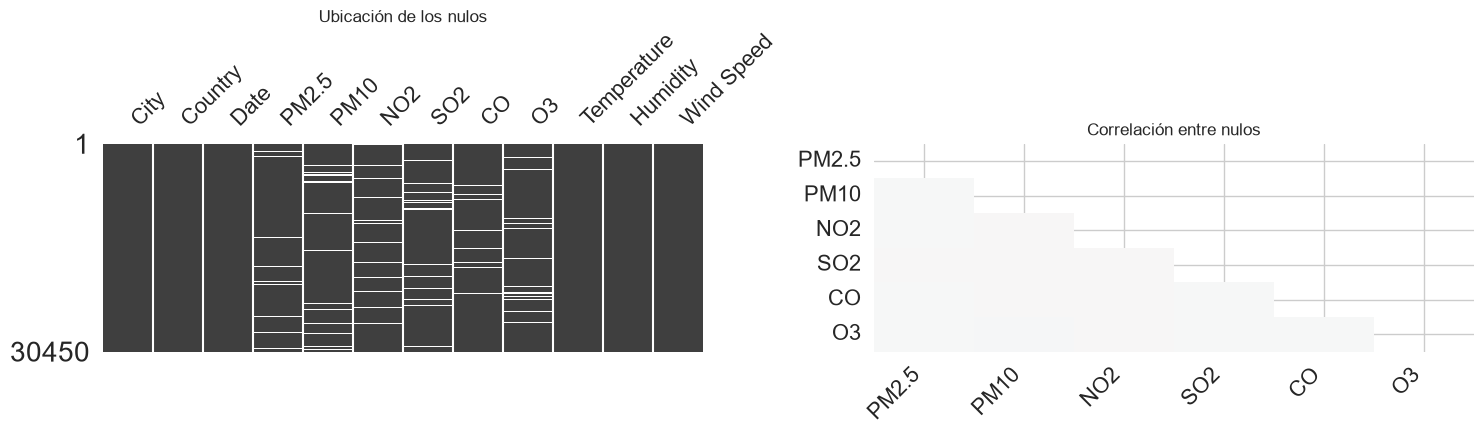

Nulos por fila:
n_nulos
0    22298
1     7105
2      971
3       74
4        2
Name: filas, dtype: int64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
msno.matrix(df, ax=axes[0], sparkline=False)
msno.heatmap(df, ax=axes[1], cbar=False)
axes[0].set_title("Ubicación de los nulos")
axes[1].set_title("Correlación entre nulos")
plt.tight_layout(); plt.show()

print("Nulos por fila:")
print(df.isna().sum(axis=1).value_counts().sort_index().rename_axis("n_nulos").rename("filas"))

## Conclusiones de la Fase I

- 30.450 filas y 12 columnas; las 6 columnas de contaminantes tienen ~5% de nulos cada una y
  las meteorológicas ninguno.
- Los nulos no se concentran en las mismas filas (la mayoría tiene 0 o 1) ni se correlacionan
  entre columnas: apuntan a pérdidas independientes, no a un fallo sistemático de un sensor.
- Las claves venían sucias: `City` con 120 variantes de escritura y fechas en formato
  estadounidense. Ambas quedaron corregidas antes de analizar.

# Fase II: Análisis exploratorio (EDA)

## Tipos de variables y variables de tiempo

In [6]:
num_cols = [c for c in df.select_dtypes("number").columns
            if perfil.loc[c, "categoria"] not in ("constante", "posible identificador")]
cat_cols = df.select_dtypes(["object", "category", "bool"]).columns.tolist()

df["mes"] = df["Date"].dt.month
df["dia_semana"] = df["Date"].dt.dayofweek
df["fin_semana"] = df["dia_semana"] >= 5

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)
display(df.groupby(["Country", "City"])["Date"].agg(["count", "min", "max"])
          .sort_values("count", ascending=False))

Numéricas: ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature', 'Humidity', 'Wind Speed']
Categóricas: ['City', 'Country']


,,count,min,max
Country,City,,,
india,mumbai,1674,2023-01-01,2023-12-28
canada,toronto,1613,2023-01-01,2023-12-27
uae,dubai,1587,2023-01-03,2023-12-28
south africa,johannesburg,1583,2023-01-01,2023-12-27
south korea,seoul,1562,2023-01-02,2023-12-28
germany,berlin,1558,2023-01-03,2023-12-28
egypt,cairo,1553,2023-01-01,2023-12-28
thailand,bangkok,1530,2023-01-01,2023-12-27
australia,sydney,1520,2023-01-02,2023-12-28


## Distribuciones numéricas y forma

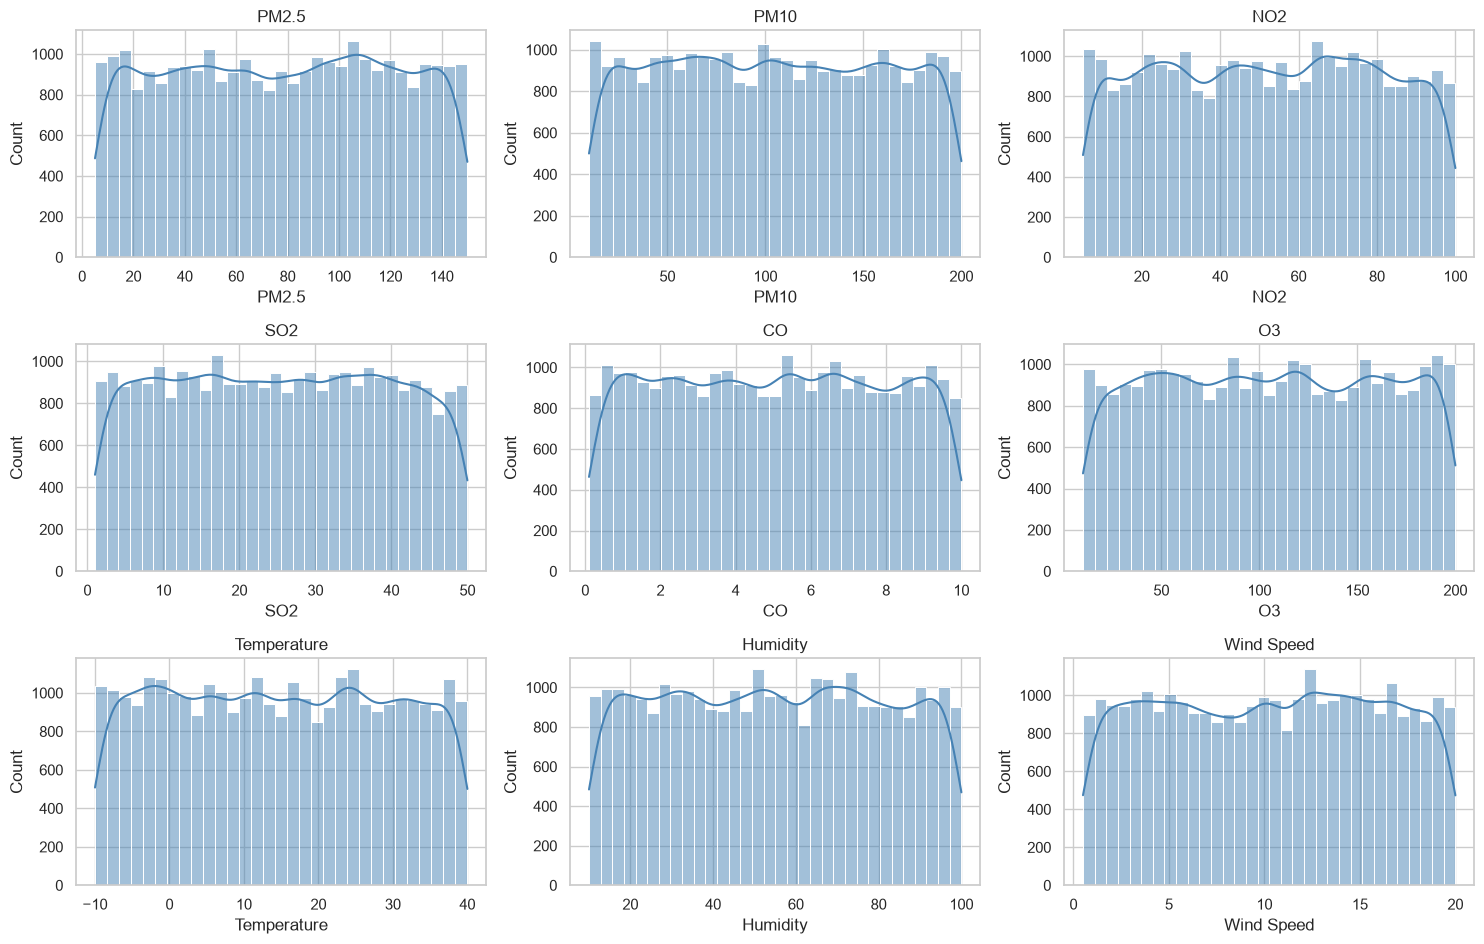

,skew,kurtosis,p_normalidad,normal (p>0.05)
PM2.5,-0.0166,-1.2068,0.0,False
PM10,0.0144,-1.2026,0.0,False
NO2,-0.0083,-1.1891,0.0,False
SO2,0.0101,-1.1898,0.0,False
CO,0.0050,-1.2024,0.0,False
O3,0.0018,-1.2033,0.0,False
Temperature,0.0180,-1.2065,0.0,False
Humidity,0.0057,-1.1942,0.0,False
Wind Speed,-0.0178,-1.2052,0.0,False


In [7]:
ncols = 3
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color="steelblue")
    ax.set_title(c)
for ax in axes[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

forma = pd.DataFrame({
    "skew": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt(),
    "p_normalidad": [stats.normaltest(df[c].dropna()).pvalue for c in num_cols],
}).round(4)
forma["normal (p>0.05)"] = forma["p_normalidad"] > 0.05
display(forma)

## Distribuciones categóricas

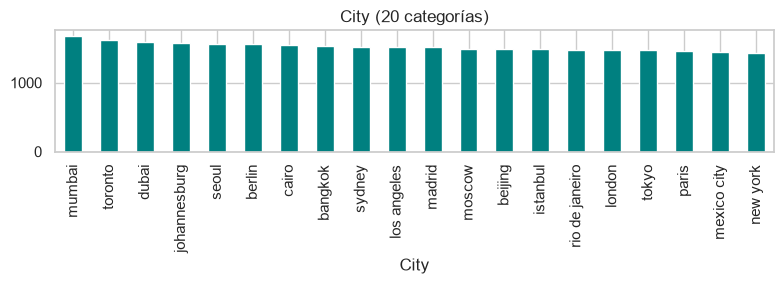

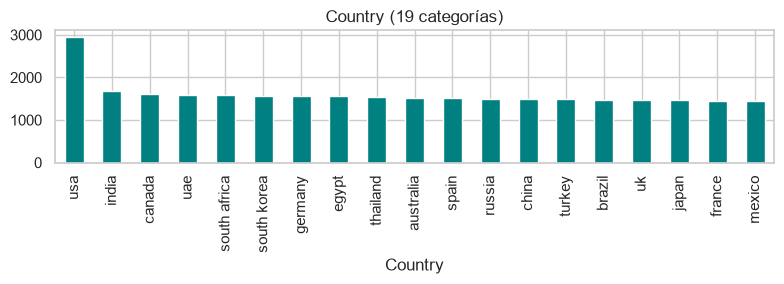

In [8]:
for c in cat_cols:
    plt.figure(figsize=(8, 3))
    df[c].value_counts(dropna=False).head(20).plot.bar(color="teal")
    plt.title(f"{c} ({df[c].nunique()} categorías)")
    plt.tight_layout(); plt.show()

## Correlaciones (Pearson vs. Spearman)

Se calculan una sola vez aquí; las preguntas siguientes reutilizan `corr_s` y `pares`.
Comparar ambos coeficientes detecta relaciones no lineales: si difieren mucho, la relación
existe pero no es recta.

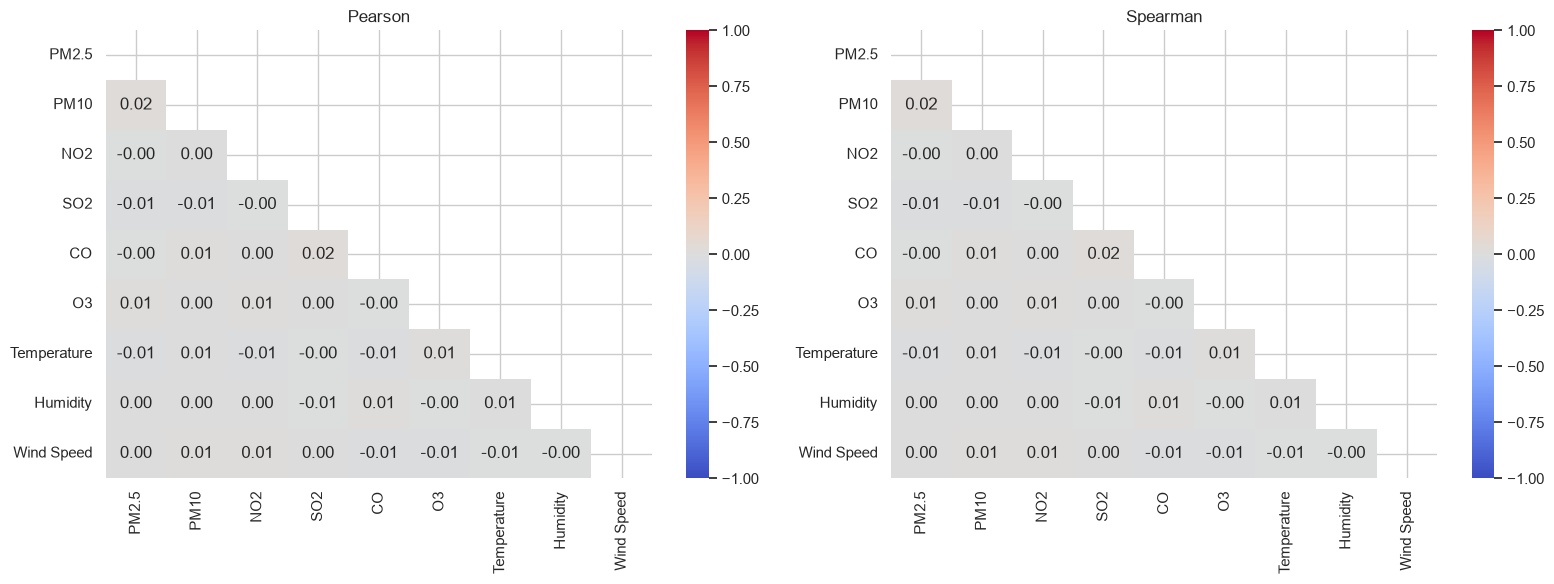

Pares más correlacionados:


,v1,v2,pearson,spearman,|dif|
21,SO2,CO,0.023,0.023,0.0
0,PM2.5,PM10,0.017,0.017,0.0
10,PM10,CO,0.014,0.014,0.0
27,CO,Temperature,-0.014,-0.014,0.0
5,PM2.5,Temperature,-0.013,-0.013,0.0
2,PM2.5,SO2,-0.013,-0.013,0.0
4,PM2.5,O3,0.013,0.013,0.0
18,NO2,Temperature,-0.013,-0.013,0.0


In [9]:
corr_p = df[num_cols].corr(method="pearson")
corr_s = df[num_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr_p, dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, m, t in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(t)
plt.tight_layout(); plt.show()

pares = pd.DataFrame([{"v1": a, "v2": b, "pearson": corr_p.loc[a, b], "spearman": corr_s.loc[a, b]}
                      for a, b in combinations(num_cols, 2)])
pares["|dif|"] = (pares["spearman"] - pares["pearson"]).abs()
pares = pares.sort_values("pearson", key=abs, ascending=False).round(3)
print("Pares más correlacionados:")
display(pares.head(8))

## Preguntas analíticas

### ¿Cómo evoluciona la contaminación en el tiempo?

Hipótesis: hay una tendencia (al alza o a la baja) y las ciudades no se mueven igual.

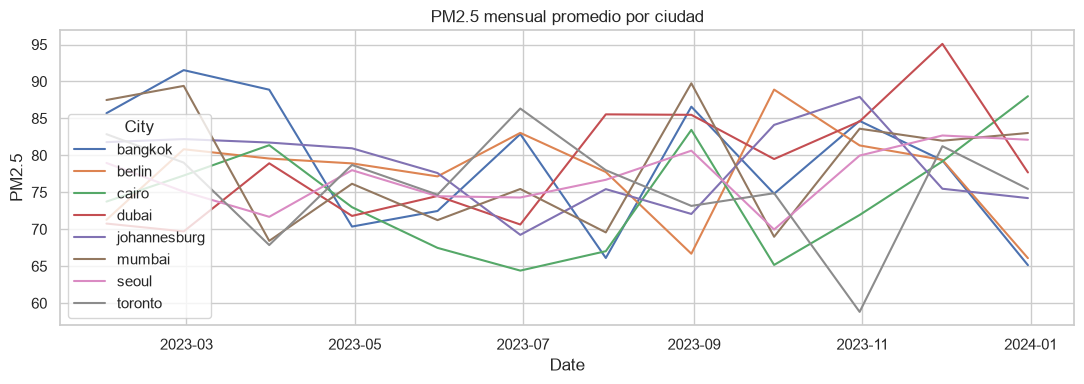

In [10]:
top_ciudades = df["City"].value_counts().head(8).index

mensual = (df[df["City"].isin(top_ciudades)]
           .set_index("Date").groupby("City")["PM2.5"].resample("ME").mean().reset_index())
plt.figure(figsize=(11, 4))
sns.lineplot(data=mensual, x="Date", y="PM2.5", hue="City")
plt.title("PM2.5 mensual promedio por ciudad"); plt.tight_layout(); plt.show()

### ¿Existe estacionalidad, y es igual en todas las ciudades?

Hipótesis: el PM2.5 tiene un patrón mensual marcado y el mes pico difiere entre ciudades
(hemisferio norte vs. sur, zonas tropicales con época seca/lluviosa).

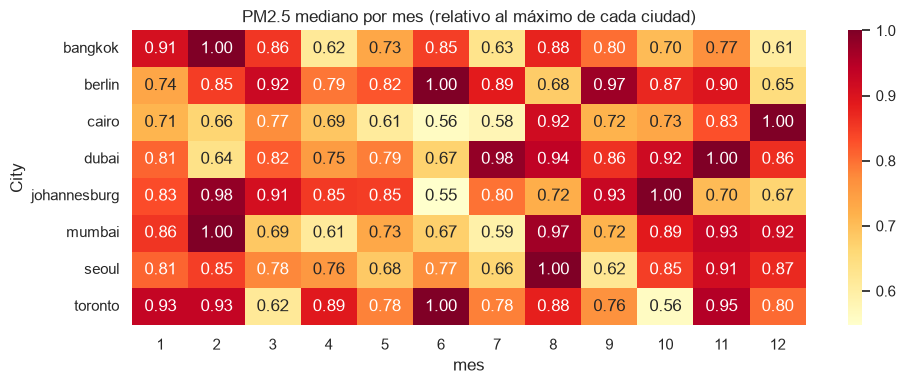

Kruskal-Wallis por mes (p < 0.05 => sí hay estacionalidad):
mumbai          0.0000
toronto         0.0000
dubai           0.0000
johannesburg    0.0237
seoul           0.4007
berlin          0.0006
cairo           0.0000
bangkok         0.0000


In [11]:
piv = (df[df["City"].isin(top_ciudades)]
       .pivot_table(index="City", columns="mes", values="PM2.5", aggfunc="median"))
plt.figure(figsize=(10, 4))
# Se normaliza por fila para comparar la forma del patrón, no el nivel
sns.heatmap(piv.div(piv.max(axis=1), axis=0), annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("PM2.5 mediano por mes (relativo al máximo de cada ciudad)")
plt.tight_layout(); plt.show()

kruskal_mes = {c: stats.kruskal(*[g["PM2.5"].dropna()
                                  for _, g in df[df["City"] == c].groupby("mes")]).pvalue
               for c in top_ciudades}
print("Kruskal-Wallis por mes (p < 0.05 => sí hay estacionalidad):")
print(pd.Series(kruskal_mes).round(4).to_string())

### ¿Difieren los niveles entre ciudades?

Hipótesis: existen diferencias fuertes y significativas entre ciudades; el nivel depende más
de la ciudad que de la variación diaria.

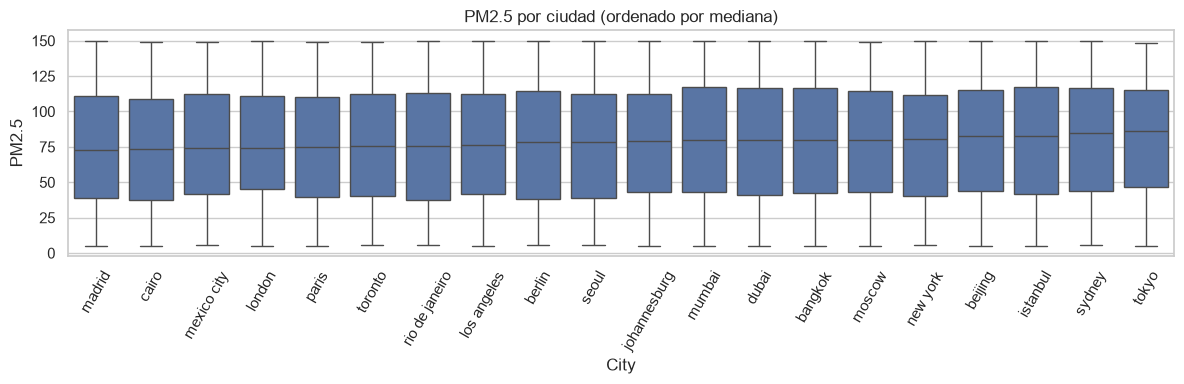

Kruskal-Wallis entre ciudades: p = 0.0001


In [12]:
orden = df.groupby("City")["PM2.5"].median().sort_values().index
plt.figure(figsize=(12, 4))
sns.boxplot(data=df, x="City", y="PM2.5", order=orden, showfliers=False)
plt.xticks(rotation=60); plt.title("PM2.5 por ciudad (ordenado por mediana)")
plt.tight_layout(); plt.show()

print("Kruskal-Wallis entre ciudades: p =",
      round(stats.kruskal(*[g["PM2.5"].dropna() for _, g in df.groupby("City")]).pvalue, 4))

### ¿Cómo influyen las variables meteorológicas?

Hipótesis: el viento fuerte dispersa contaminantes (correlación negativa), la temperatura se
asocia positivamente con el O3 y la humedad alta favorece el PM2.5.

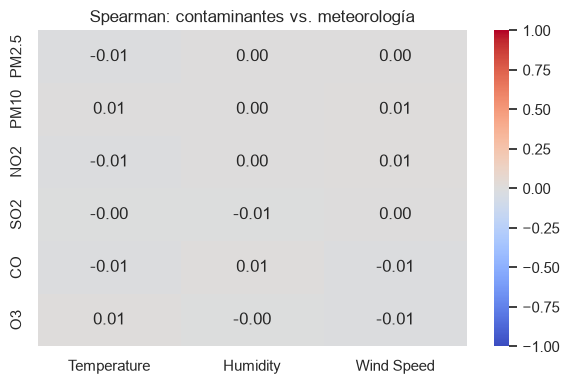

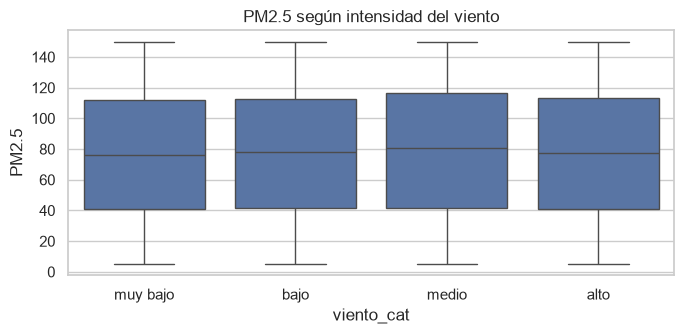

In [13]:
plt.figure(figsize=(6, 4))
sns.heatmap(corr_s.loc[POLL, METEO], annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)
plt.title("Spearman: contaminantes vs. meteorología"); plt.tight_layout(); plt.show()

df["viento_cat"] = pd.qcut(df["Wind Speed"], 4, labels=["muy bajo", "bajo", "medio", "alto"])
plt.figure(figsize=(7, 3.5))
sns.boxplot(data=df, x="viento_cat", y="PM2.5", showfliers=False)
plt.title("PM2.5 según intensidad del viento"); plt.tight_layout(); plt.show()

### ¿Qué contaminantes se mueven juntos?

Hipótesis: PM2.5 y PM10 muy correlacionados (r > 0.8), O3 negativo con NO2, y CO con NO2 por
compartir fuente (tráfico).

,v1,v2,pearson,spearman,|dif|
21,SO2,CO,0.023,0.023,0.0
0,PM2.5,PM10,0.017,0.017,0.0
10,PM10,CO,0.014,0.014,0.0
2,PM2.5,SO2,-0.013,-0.013,0.0
4,PM2.5,O3,0.013,0.013,0.0


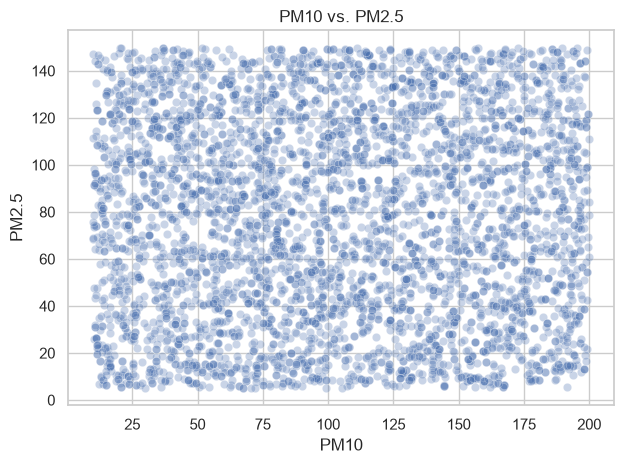

In [14]:
display(pares[pares["v1"].isin(POLL) & pares["v2"].isin(POLL)].head(5))

sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=RANDOM_STATE),
                x="PM10", y="PM2.5", alpha=.3)
plt.title("PM10 vs. PM2.5"); plt.tight_layout(); plt.show()

### ¿Con qué frecuencia se superan los umbrales de la OMS?

Guías OMS 2021 para 24 h: PM2.5 = 15, PM10 = 45, NO2 = 25 µg/m³. Los datos ya son diarios,
así que se comparan directamente.

In [15]:
umbrales = {"PM2.5": 15, "PM10": 45, "NO2": 25}
exced = pd.DataFrame({f"% días > OMS ({c})": (df[c] > u).groupby(df["City"]).mean() * 100
                      for c, u in umbrales.items()}).round(1)
display(exced.sort_values("% días > OMS (PM2.5)", ascending=False))

,% días > OMS (PM2.5),% días > OMS (PM10),% días > OMS (NO2)
City,,,
johannesburg,89.9,75.9,75.3
madrid,89.6,78.2,74.1
london,89.5,77.4,74.4
tokyo,89.2,79.9,72.6
beijing,88.9,75.5,73.2
bangkok,88.8,75.9,70.5
toronto,88.5,76.0,73.2
paris,88.3,75.0,77.0
mumbai,88.1,79.5,76.6


### ¿Cambia el patrón entre días laborales y fines de semana?

Hipótesis: menos tráfico el fin de semana implica menos NO2 y CO.

In [16]:
comparacion = []
for c in ["NO2", "CO", "PM2.5"]:
    finde = df.loc[df["fin_semana"], c].dropna()
    laboral = df.loc[~df["fin_semana"], c].dropna()
    comparacion.append({"variable": c,
                        "mediana_laboral": laboral.median(),
                        "mediana_finde": finde.median(),
                        "p_Mann-Whitney": stats.mannwhitneyu(finde, laboral).pvalue})
display(pd.DataFrame(comparacion).set_index("variable").round(4))

,mediana_laboral,mediana_finde,p_Mann-Whitney
variable,,,
NO2,52.15,52.75,0.6192
CO,5.06,5.09,0.4818
PM2.5,78.26,78.11,0.2417


### Preguntas de calidad del dato

Rangos imposibles, duplicados, coherencia ciudad-país y distribución de los nulos.

In [17]:
rangos = df[POLL + METEO].agg(["min", "max"]).T.round(2)
rangos["negativos"] = (df[POLL + METEO] < 0).sum()
rangos["ceros"] = (df[POLL + METEO] == 0).sum()
display(rangos)

print("Duplicados exactos:", df.duplicated().sum(),
      "| misma City+Date:", df.duplicated(subset=["City", "Date"]).sum())
ambiguas = df.groupby("City")["Country"].nunique().loc[lambda s: s > 1]
print("Ciudades asignadas a más de un país:", ambiguas.to_dict() or "ninguna")

,min,max,negativos,ceros
PM2.5,5.02,149.98,0,0
PM10,10.00,200.00,0,0
NO2,5.01,100.00,0,0
SO2,1.00,49.99,0,0
CO,0.10,10.00,0,0
O3,10.04,200.00,0,0
Temperature,-10.00,40.00,6309,7
Humidity,10.01,99.99,0,0
Wind Speed,0.50,20.00,0,0


Duplicados exactos: 13897 | misma City+Date: 25375
Ciudades asignadas a más de un país: ninguna


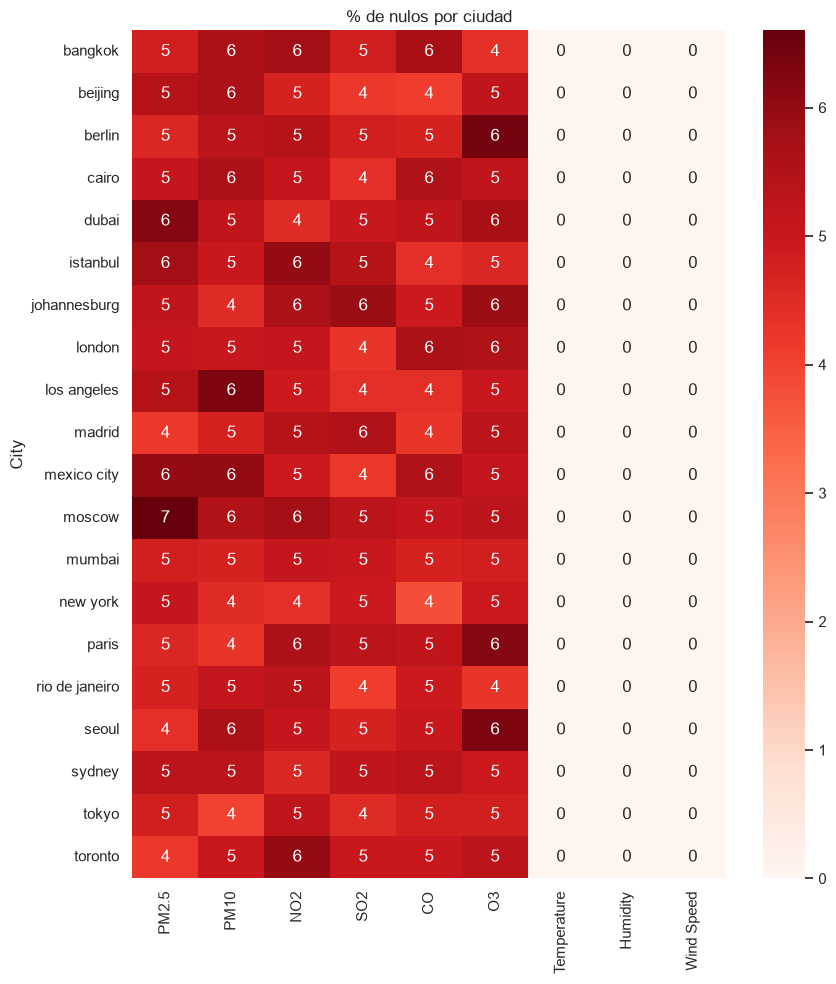

In [18]:
nulos_ciudad = df.groupby("City")[POLL + METEO].apply(lambda x: x.isna().mean() * 100).round(1)
plt.figure(figsize=(9, 0.4 * len(nulos_ciudad) + 2))
sns.heatmap(nulos_ciudad, annot=True, cmap="Reds", fmt=".0f")
plt.title("% de nulos por ciudad"); plt.tight_layout(); plt.show()

## Conclusiones de la Fase II

- Todas las variables son prácticamente uniformes (curtosis ≈ -1.2, asimetría ≈ 0) y ninguna
  pasa el test de normalidad: hay que usar estadística no paramétrica.
- Las correlaciones entre variables son casi nulas (|ρ| < 0.05), incluso entre PM2.5 y PM10:
  el dataset no reproduce las relaciones físicas esperadas.
- **Ciudad y mes sí producen diferencias significativas** (Kruskal-Wallis p = 0.0001 entre
  ciudades; p < 0.05 en 7 de las 8 ciudades principales al comparar meses). El fin de semana es
  la única partición sin efecto (Mann-Whitney p > 0.18 en NO2, CO y PM2.5): el nivel de
  contaminación depende de dónde y cuándo, pero no de si es día laboral o no.
- El problema real del dataset es de calidad: ~34% de filas duplicadas exactas (antes de
  normalizar texto; más aún después, ver Fase III) y ~5% de nulos por contaminante repartidos
  de forma pareja entre ciudades.

# Fase III: Limpieza de datos

In [19]:
df_clean = df.copy(deep=True).sort_values(["City", "Date"]).reset_index(drop=True)
NUM = [c for c in POLL + METEO if c in df_clean.columns]

## Duplicados (primer paso)

El texto y las fechas ya se estandarizaron en la Fase I (ver bitácora de decisiones); aquí se
resuelven los duplicados que esa normalización dejó visibles.

Se hace **antes** de imputar por dos razones: no tiene sentido imputar valores en filas que
luego se eliminan, y el criterio de desempate entre registros con la misma clave es la
completitud, que después de imputar sería idéntica para todos.

In [20]:
n_exactos = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
registrar("III-duplicados", "todas", f"Eliminar {n_exactos} filas",
          "Registros idénticos en todas las columnas")
print("Duplicados exactos eliminados:", n_exactos)

parciales = df_clean.duplicated(subset=CLAVES, keep=False)
print("Filas con clave Country+City+Date repetida:", int(parciales.sum()))
display(df_clean[parciales].sort_values(CLAVES).head(6))

# Se conserva el registro más completo de cada clave
n_parciales = int(df_clean.duplicated(subset=CLAVES).sum())
df_clean = (df_clean.assign(_completitud=df_clean.notna().sum(axis=1))
                    .sort_values("_completitud", ascending=False)
                    .drop_duplicates(subset=CLAVES, keep="first")
                    .drop(columns="_completitud")
                    .sort_index())
registrar("III-duplicados", "+".join(CLAVES), f"Eliminar {n_parciales} filas",
          "Misma clave de negocio: se conserva el registro más completo")
print("Filas finales:", f"{len(df_clean):,}")

Duplicados exactos eliminados: 13897
Filas con clave Country+City+Date repetida: 15534


,City,Country,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind Speed,mes,dia_semana,fin_semana,viento_cat
0,bangkok,thailand,2023-01-01,104.65,129.93,87.44,46.85,NaN,134.22,22.43,28.17,15.70,1,6,True,alto
1,bangkok,thailand,2023-01-01,130.50,135.42,10.63,9.58,4.81,42.17,-2.48,76.42,6.94,1,6,True,bajo
2,bangkok,thailand,2023-01-01,104.65,129.93,87.44,46.85,7.19,NaN,22.43,28.17,15.70,1,6,True,alto
3,bangkok,thailand,2023-01-01,104.65,NaN,87.44,46.85,7.19,134.22,22.43,28.17,15.70,1,6,True,alto
4,bangkok,thailand,2023-01-01,146.15,17.85,8.16,26.30,6.47,32.08,-2.45,40.91,18.89,1,6,True,alto
6,bangkok,thailand,2023-01-01,104.65,129.93,87.44,46.85,7.19,134.22,22.43,28.17,15.70,1,6,True,alto


Filas finales: 5,075


## Valores nulos: diagnóstico y plan

Para cada columna con nulos se mide en una sola tabla:

- `pct_nulos`: cuánto falta.
- `vars_sig_MAR`: variables cuya distribución cambia significativamente entre filas con y sin
  nulo (Mann-Whitney). Muchas ⇒ el nulo depende de otras variables (MAR).
- `r_max`: correlación máxima con otra numérica. Solo con `r_max` alto tendría sentido una
  imputación multivariada (regresión); si no, el modelo no tendría de dónde predecir.

In [21]:
corr_num = df_clean[NUM].corr("spearman").abs()

def plan_imputacion(data, cols):
    filas = []
    for c in cols:
        s = data[c]
        pct = s.isna().mean() * 100
        ind = s.isna()
        n_sig = sum(stats.mannwhitneyu(data.loc[ind, o].dropna(),
                                       data.loc[~ind, o].dropna()).pvalue < 0.05
                    for o in cols if o != c and data.loc[ind, o].notna().sum() > 5)
        r_max = corr_num[c].drop(c).max()
        if pct > 60:
            est, motivo = "eliminar_columna", f"{pct:.0f}% de nulos"
        elif r_max > 0.5 and n_sig >= 2:
            est, motivo = "revisar_multivariada", f"MAR probable (r_max={r_max:.2f})"
        elif pct < 5:
            est, motivo = "interpolacion", f"{pct:.1f}% de nulos en serie diaria por ciudad"
        elif abs(s.skew()) > 1:
            est, motivo = "mediana_ciudad", f"skew={s.skew():.2f} (sesgada)"
        else:
            est, motivo = "media_ciudad", f"skew={s.skew():.2f} (simétrica)"
        filas.append({"columna": c, "pct_nulos": round(pct, 2), "vars_sig_MAR": n_sig,
                      "r_max": round(r_max, 3), "estrategia": est, "motivo": motivo})
    return pd.DataFrame(filas).set_index("columna")

num_nulas = [c for c in NUM if df_clean[c].isna().any()]
plan = plan_imputacion(df_clean, num_nulas)
display(plan)

,pct_nulos,vars_sig_MAR,r_max,estrategia,motivo
columna,,,,,
PM2.5,0.63,0,0.019,interpolacion,0.6% de nulos en serie diaria por ciudad
PM10,0.47,1,0.022,interpolacion,0.5% de nulos en serie diaria por ciudad
NO2,0.41,0,0.024,interpolacion,0.4% de nulos en serie diaria por ciudad
SO2,0.57,1,0.019,interpolacion,0.6% de nulos en serie diaria por ciudad
CO,0.49,1,0.022,interpolacion,0.5% de nulos en serie diaria por ciudad
O3,0.49,0,0.024,interpolacion,0.5% de nulos en serie diaria por ciudad


## Aplicación de la estrategia y validación

Cada método se aplica **por ciudad** (cada ciudad tiene su propio nivel base), con respaldo
global para los huecos que queden. La validación compara la distribución antes y después: si
el test KS no detecta diferencia, la imputación no deformó la variable.

,media_antes,media_despues,std_antes,std_despues,KS_p,distribucion_intacta
PM2.5,77.801,77.781,41.725,41.644,1.0,True
PM10,104.792,104.798,54.782,54.705,1.0,True
NO2,52.070,52.122,27.265,27.238,1.0,True
SO2,25.297,25.304,14.082,14.055,1.0,True
CO,5.022,5.028,2.865,2.862,1.0,True
O3,106.004,106.029,54.531,54.472,1.0,True


Nulos restantes en todo el dataset: 0


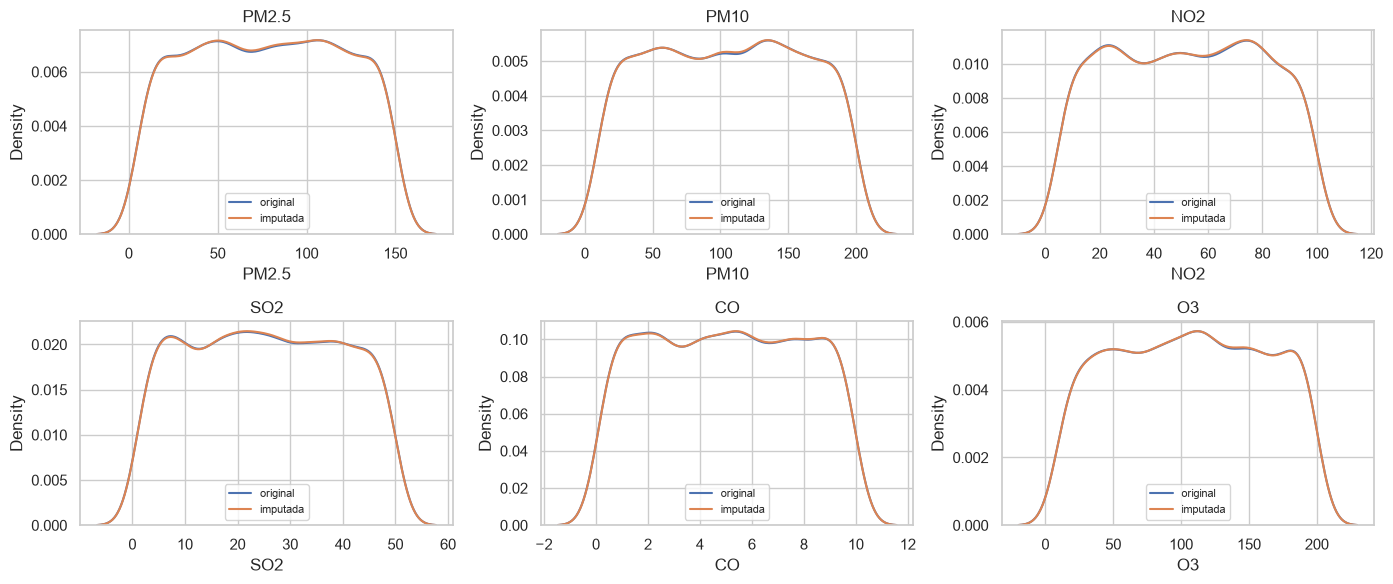

In [22]:
IMPUTADORES = {
    "interpolacion": lambda d, c: d.groupby("City")[c].transform(
        lambda s: s.interpolate(limit=3, limit_direction="both")),
    "mediana_ciudad": lambda d, c: d.groupby("City")[c].transform("median"),
    "media_ciudad": lambda d, c: d.groupby("City")[c].transform("mean"),
}

antes = df_clean[num_nulas].copy()
for c, fila in plan.iterrows():
    if fila["estrategia"] == "eliminar_columna":
        df_clean = df_clean.drop(columns=c)
        registrar("III-nulos", c, "Eliminar columna", fila["motivo"])
    else:
        n = int(df_clean[c].isna().sum())
        df_clean[c] = (df_clean[c]
                       .fillna(IMPUTADORES[fila["estrategia"]](df_clean, c))
                       .fillna(df_clean[c].median()))
        registrar("III-nulos", c, f"{fila['estrategia']} ({n} valores)", fila["motivo"])

imputadas = [c for c in num_nulas if c in df_clean.columns]
validacion = pd.DataFrame({
    "media_antes": antes[imputadas].mean(),
    "media_despues": df_clean[imputadas].mean(),
    "std_antes": antes[imputadas].std(),
    "std_despues": df_clean[imputadas].std(),
    "KS_p": [stats.ks_2samp(antes[c].dropna(), df_clean[c]).pvalue for c in imputadas],
}).round(3)
validacion["distribucion_intacta"] = validacion["KS_p"] > 0.05
display(validacion)
print("Nulos restantes en todo el dataset:", int(df_clean.isna().sum().sum()))

nrows = int(np.ceil(len(imputadas) / 3))
fig, axes = plt.subplots(nrows, 3, figsize=(14, 3 * nrows))
for ax, c in zip(np.array(axes).ravel(), imputadas):
    sns.kdeplot(antes[c].dropna(), label="original", ax=ax)
    sns.kdeplot(df_clean[c], label="imputada", ax=ax)
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Outliers

Tres criterios univariados (IQR, Z-score y Z modificado por MAD) más uno multivariado
(distancia de Mahalanobis robusta). Se marca como outlier de consenso el que detectan al
menos dos criterios; **no se eliminan**, se documentan para decidir en la Fase IV.

In [23]:
def flags_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    mad = stats.median_abs_deviation(s.dropna())
    return pd.DataFrame({
        "IQR": (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr),
        "Z": ((s - s.mean()) / s.std()).abs() > 3,
        "MAD": (0.6745 * (s - s.median()) / mad).abs() > 3.5 if mad else False,
    })

flags = {c: flags_outliers(df_clean[c]) for c in NUM if c in df_clean.columns}
consenso = pd.DataFrame({c: f.sum(axis=1) >= 2 for c, f in flags.items()})

resumen_out = pd.DataFrame({
    c: {**f.sum().to_dict(),
        "consenso (>=2)": int(consenso[c].sum()),
        "% consenso": round(consenso[c].mean() * 100, 2)}
    for c, f in flags.items()
}).T
display(resumen_out)

,IQR,Z,MAD,consenso (>=2),% consenso
PM2.5,0.0,0.0,0.0,0.0,0.0
PM10,0.0,0.0,0.0,0.0,0.0
NO2,0.0,0.0,0.0,0.0,0.0
SO2,0.0,0.0,0.0,0.0,0.0
CO,0.0,0.0,0.0,0.0,0.0
O3,0.0,0.0,0.0,0.0,0.0
Temperature,0.0,0.0,0.0,0.0,0.0
Humidity,0.0,0.0,0.0,0.0,0.0
Wind Speed,0.0,0.0,0.0,0.0,0.0


In [24]:
cols_mv = [c for c in POLL if c in df_clean.columns][:5]
datos_mv = df_clean[cols_mv].dropna()
d2 = MinCovDet(random_state=RANDOM_STATE).fit(datos_mv).mahalanobis(datos_mv)
out_mv = pd.Series(d2 > stats.chi2.ppf(0.999, df=len(cols_mv)), index=datos_mv.index)
print(f"Outliers multivariados (Mahalanobis robusta): {out_mv.sum()} ({out_mv.mean():.2%})")

Outliers multivariados (Mahalanobis robusta): 0 (0.00%)


## Bitácora de decisiones

In [25]:
display(pd.DataFrame(decisiones))

,fase,columna,accion,justificacion
0,I-claves,City,Normalizar texto,120 variantes por mayúsculas/espacios → 20 reales
1,I-claves,Country,Normalizar texto,19 variantes por mayúsculas/espacios → 19 reales
2,I-claves,Date,Parsear con formato %m/%d/%Y,0 fechas inválidas (con %d/%m/%Y serían 17283)
3,III-duplicados,todas,Eliminar 13897 filas,Registros idénticos en todas las columnas
4,III-duplicados,City+Country+Date,Eliminar 11478 filas,Misma clave de negocio: se conserva el registr...
5,III-nulos,PM2.5,interpolacion (32 valores),0.6% de nulos en serie diaria por ciudad
6,III-nulos,PM10,interpolacion (24 valores),0.5% de nulos en serie diaria por ciudad
7,III-nulos,NO2,interpolacion (21 valores),0.4% de nulos en serie diaria por ciudad
8,III-nulos,SO2,interpolacion (29 valores),0.6% de nulos en serie diaria por ciudad
9,III-nulos,CO,interpolacion (25 valores),0.5% de nulos en serie diaria por ciudad


# Fase IV: Transformación, normalización e ingeniería de características

El orden importa: **derivadas → codificación → escalado**. Si se escala primero, las variables
creadas después quedan en otra escala; si se codifica al final, las dummies terminan escaladas
sin necesidad.

El entregable final es **un único CSV en unidades reales** (`df_procesado`), que se exporta al
cerrar la Fase V. La matriz escalada y codificada (`df_modelo`) se construye igual, porque es
lo que permite auditar el efecto del escalado en la Fase V, pero no se exporta: es una
representación alternativa de columnas que ya están en el entregable.

## 1. Variables derivadas

| Variable | Qué aporta |
|---|---|
| `ratio_pm` | Fracción fina PM2.5/PM10: distingue combustión de polvo resuspendido |
| `n_excedencias_oms` | Cuántas guías OMS supera el registro (0-3): severidad por fila |
| `pm25_vs_ciudad` | Desviación respecto a la mediana de su ciudad: separa el día malo de la ciudad contaminada |
| `pm25_movil_7d`, `pm25_delta` | Tendencia local y salto diario |
| `trimestre_met`, `mes_sin/cos`, `dia_sem_sin/cos` | Descomposición temporal |

Dos decisiones con motivo:

- La media móvil usa una ventana **temporal** de 7 días (`rolling("7D")`), no de 7 filas: cada
  ciudad tiene ~253 días de los 336 posibles, así que contar filas mezclaría fechas lejanas.
- El trimestre se nombra `DEF/MAM/JJA/SON` en vez de invierno/verano porque el dataset tiene
  ciudades de ambos hemisferios: diciembre no es la misma estación en moscow que en sydney.

In [26]:
df_final = df_clean.copy(deep=True).sort_values(["City", "Date"])

# Fracción fina: PM2.5 es un subconjunto de PM10, el ratio debería caer en (0, 1]
df_final["ratio_pm"] = df_final["PM2.5"] / df_final["PM10"]
df_final["ratio_pm_imposible"] = df_final["ratio_pm"] > 1

# Severidad: reutiliza los umbrales OMS de la Fase II
df_final["n_excedencias_oms"] = sum((df_final[c] > u).astype(int) for c, u in umbrales.items())

# Nivel base de la ciudad vs. el día concreto
df_final["pm25_vs_ciudad"] = (df_final["PM2.5"]
                              - df_final.groupby("City")["PM2.5"].transform("median"))

# Tendencia local: ventana de 7 días reales. El frame ya está ordenado por City y Date,
# así que la serie devuelta se alinea posición a posición.
df_final["pm25_movil_7d"] = (df_final.set_index("Date").groupby("City")["PM2.5"]
                             .rolling("7D").mean().values)
df_final["pm25_delta"] = df_final.groupby("City")["PM2.5"].diff().fillna(0)

# Descomposición temporal (las cíclicas evitan que diciembre y enero queden a 11 de distancia)
TRIMESTRE = {12: "DEF", 1: "DEF", 2: "DEF", 3: "MAM", 4: "MAM", 5: "MAM",
             6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
df_final["trimestre_met"] = df_final["mes"].map(TRIMESTRE)
df_final["mes_sin"] = np.sin(2 * np.pi * df_final["mes"] / 12)
df_final["mes_cos"] = np.cos(2 * np.pi * df_final["mes"] / 12)
df_final["dia_sem_sin"] = np.sin(2 * np.pi * df_final["dia_semana"] / 7)
df_final["dia_sem_cos"] = np.cos(2 * np.pi * df_final["dia_semana"] / 7)

DERIVADAS = ["ratio_pm", "n_excedencias_oms", "pm25_vs_ciudad", "pm25_movil_7d",
             "pm25_delta", "mes_sin", "mes_cos", "dia_sem_sin", "dia_sem_cos"]
display(df_final[DERIVADAS].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
ratio_pm,5075.0,1.231,1.546,0.027,0.399,0.744,1.364,13.485
n_excedencias_oms,5075.0,2.531,0.608,0.000,2.000,3.000,3.000,3.000
pm25_vs_ciudad,5075.0,-0.218,41.654,-78.750,-35.752,0.000,35.510,79.475
pm25_movil_7d,5075.0,77.509,19.252,5.370,64.756,77.765,90.186,148.780
pm25_delta,5075.0,0.063,58.435,-143.350,-41.760,0.000,41.870,142.420
mes_sin,5075.0,-0.005,0.709,-1.000,-0.866,0.000,0.500,1.000
mes_cos,5075.0,-0.006,0.706,-1.000,-0.866,-0.000,0.500,1.000
dia_sem_sin,5075.0,0.001,0.708,-0.975,-0.782,0.000,0.782,0.975
dia_sem_cos,5075.0,-0.014,0.706,-0.901,-0.901,-0.223,0.623,1.000


### Validación de las derivadas

Una derivada solo sirve si es correcta y si aporta información que no estaba. Se comprueban
las dos cosas: coherencia física y correlación máxima con las variables de origen.

In [27]:
imposibles = df_final["ratio_pm_imposible"].mean() * 100
print(f"PM2.5 > PM10 (físicamente imposible): {imposibles:.1f}% de las filas "
      f"| ratio máximo = {df_final['ratio_pm'].max():.1f}")

aporte = pd.DataFrame({
    "max |rho| con las originales": [df_final[NUM + [c]].corr("spearman")[c].drop(c).abs().max()
                                     for c in DERIVADAS],
}, index=DERIVADAS).round(3)
aporte["redundante (>0.95)"] = aporte["max |rho| con las originales"] > 0.95
display(aporte)

PM2.5 > PM10 (físicamente imposible): 35.8% de las filas | ratio máximo = 13.5


,max |rho| con las originales,redundante (>0.95)
ratio_pm,0.682,False
n_excedencias_oms,0.476,False
pm25_vs_ciudad,0.997,True
pm25_movil_7d,0.442,False
pm25_delta,0.694,False
mes_sin,0.025,False
mes_cos,0.021,False
dia_sem_sin,0.026,False
dia_sem_cos,0.030,False


## 2. Codificación de variables categóricas

Reglas aplicadas:

- `City` (20 categorías, nominal) → **One-Hot con `drop_first`**: 19 columnas.
- `Country` **no se codifica**. `City` determina `Country` de forma funcional, así que sus
  dummies son una suma exacta de las de `City`. Es multicolinealidad perfecta, más grave que la
  trampa clásica de la dummy, y se comprueba abajo con el rango de la matriz.
- `viento_cat` (ordinal real) → **Ordinal Encoding** con el orden declarado a mano, no el
  alfabético.
- `fin_semana` (binaria) → entero; una variable de dos niveles no necesita One-Hot.
- `trimestre_met` se queda solo en `df_procesado`: para el modelo ya está `mes_sin/mes_cos`, que
  codifica lo mismo sin crear cuatro columnas.

In [28]:
# La trampa de las variables ficticias, con números
todas_city = pd.get_dummies(df_final["City"], prefix="city", dtype=int)
print("Suma por fila de TODAS las dummies:", np.unique(todas_city.sum(axis=1)),
      "→ constante, colineal con el intercepto")

dummies_city = pd.get_dummies(df_final["City"], prefix="city", drop_first=True, dtype=int)
print(f"Con drop_first: {dummies_city.shape[1]} columnas en vez de {todas_city.shape[1]}")

# Redundancia City–Country: el rango revela cuántas columnas son realmente independientes
dummies_pais = pd.get_dummies(df_final["Country"], prefix="pais", dtype=int)
juntas = np.hstack([todas_city.values, dummies_pais.values])
print(f"[City | Country]: {juntas.shape[1]} columnas pero rango {np.linalg.matrix_rank(juntas)}"
      f" → {juntas.shape[1] - np.linalg.matrix_rank(juntas)} columnas redundantes")
print("City → Country es funcional:",
      bool((df_final.groupby("City")["Country"].nunique() == 1).all()))

ORDEN_VIENTO = ["muy bajo", "bajo", "medio", "alto"]
df_final["viento_ord"] = pd.Categorical(df_final["viento_cat"],
                                        categories=ORDEN_VIENTO, ordered=True).codes
df_final["fin_semana_int"] = df_final["fin_semana"].astype(int)

Suma por fila de TODAS las dummies: [1] → constante, colineal con el intercepto
Con drop_first: 19 columnas en vez de 20
[City | Country]: 39 columnas pero rango 20 → 19 columnas redundantes
City → Country es funcional: True


### Target Encoding: se evalúa y se descarta

Codificar `City` por la media de PM2.5 sería más compacto que 19 dummies, pero solo aporta si
el nivel medio cambia de verdad entre ciudades. Se mide *out-of-fold* (con KFold) para que la
media no incluya la fila que se está codificando, que es de donde sale la fuga de datos.

In [29]:
te = pd.Series(np.nan, index=range(len(df_final)))
for tr, va in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(df_final):
    medias = df_final.iloc[tr].groupby("City")["PM2.5"].mean()
    te.iloc[va] = df_final.iloc[va]["City"].map(medias).values

var_entre = df_final.groupby("City")["PM2.5"].mean().var()
print(f"Correlación del encoding con el target: {te.corr(pd.Series(df_final['PM2.5'].values)):.4f}")
print(f"Varianza entre ciudades / varianza total: {var_entre / df_final['PM2.5'].var():.5f}")
print("Decisión: se descarta. El nivel medio por ciudad es prácticamente idéntico "
      "(coherente con el Kruskal no significativo de la Fase II), así que aportaría ruido "
      "y riesgo de fuga a cambio de nada.")

Correlación del encoding con el target: -0.0418
Varianza entre ciudades / varianza total: 0.00262
Decisión: se descarta. El nivel medio por ciudad es prácticamente idéntico (coherente con el Kruskal no significativo de la Fase II), así que aportaría ruido y riesgo de fuga a cambio de nada.


### Control de multicolinealidad (VIF)

El VIF mide cuánto se puede predecir cada columna con las demás: `VIF = 1/(1-R²)`. Por encima
de 10 la columna es casi redundante; infinito significa combinación lineal exacta.

In [30]:
def vif(X):
    """Factor de inflación de la varianza de cada columna frente al resto."""
    X = X.astype(float)
    resultado = {}
    for c in X.columns:
        A = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(A, X[c].values, rcond=None)
        resid = X[c].values - A @ coef
        ss_tot = ((X[c].values - X[c].mean()) ** 2).sum()
        r2 = 1 - resid @ resid / ss_tot if ss_tot > 0 else 0.0
        resultado[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(resultado).sort_values(ascending=False)

CONTINUAS = NUM + ["ratio_pm", "n_excedencias_oms", "pm25_vs_ciudad",
                   "pm25_movil_7d", "pm25_delta"]
CODIFICADAS = ["viento_ord", "fin_semana_int", "mes_sin", "mes_cos",
               "dia_sem_sin", "dia_sem_cos"]

X = pd.concat([df_final[CONTINUAS + CODIFICADAS], dummies_city], axis=1)
vif_inicial = vif(X)
display(vif_inicial.head(8).round(2).to_frame("VIF"))

,VIF
PM2.5,inf
city_paris,inf
city_rio de janeiro,inf
city_berlin,inf
city_cairo,inf
city_beijing,inf
pm25_vs_ciudad,inf
city_seoul,inf


Dos columnas hay que sacar del modelo, y por motivos distintos:

- `pm25_vs_ciudad` es `PM2.5` menos una constante por ciudad, y esa constante ya está en las
  dummies: combinación lineal exacta.
- `viento_ord` son los cuartiles de `Wind Speed`, así que repite la misma información en peor
  resolución. Se conserva la continua.

Las dos siguen en `df_procesado`, donde son útiles para leer; solo salen de `df_modelo`.

In [31]:
EXCLUIR_MODELO = ["pm25_vs_ciudad", "viento_ord"]
X = X.drop(columns=EXCLUIR_MODELO)
vif_final = vif(X)
display(vif_final.head(8).round(2).to_frame("VIF"))

altos = vif_final[vif_final > 10]
print("Columnas con VIF > 10 tras la depuración:", list(altos.index) or "ninguna")

,VIF
PM2.5,3.93
fin_semana_int,2.82
dia_sem_sin,2.73
pm25_delta,2.64
ratio_pm,2.46
n_excedencias_oms,1.96
city_toronto,1.92
city_johannesburg,1.91


Columnas con VIF > 10 tras la depuración: ninguna


## 3. Escalado numérico

La elección se hace con una regla explícita sobre dos indicadores:

- **`IQR/std`**: vale 1.35 en una normal y baja cuanto más pesadas son las colas (la desviación
  crece más rápido que el rango intercuartílico). Por encima de 1.35 no hay colas que temer.
- **% de outliers de consenso** (los tres criterios de la Fase III).

Con eso, y **decidiendo columna por columna**, porque no todas se comportan igual: colas
pesadas → `RobustScaler`; si no, rango acotado y estable → `MinMaxScaler`; en cualquier otro
caso → `StandardScaler`.

In [32]:
A_ESCALAR = [c for c in CONTINUAS if c not in EXCLUIR_MODELO]

diag = pd.DataFrame({
    "skew": df_final[A_ESCALAR].skew(),
    "curtosis": df_final[A_ESCALAR].kurt(),
    "IQR/std": ((df_final[A_ESCALAR].quantile(.75) - df_final[A_ESCALAR].quantile(.25))
                / df_final[A_ESCALAR].std()),
    "% outliers": [ (flags_outliers(df_final[c]).sum(axis=1) >= 2).mean() * 100
                    for c in A_ESCALAR ],
    "p99/max": df_final[A_ESCALAR].quantile(.99) / df_final[A_ESCALAR].max(),
}).round(3)

MOTIVOS = {
    "RobustScaler": "colas pesadas: la mediana y el IQR aguantan donde la media y el rango no",
    "MinMaxScaler": "sin colas pesadas y con rango acotado y estable (p99 ≈ max)",
    "StandardScaler": "sin colas pesadas pero con rango abierto",
}

def elegir_escalador(fila):
    if fila["% outliers"] > 5 or fila["IQR/std"] < 1.0:
        return "RobustScaler"
    if abs(fila["p99/max"]) > 0.9:
        return "MinMaxScaler"
    return "StandardScaler"

diag["escalador"] = diag.apply(elegir_escalador, axis=1)
display(diag)

,skew,curtosis,IQR/std,% outliers,p99/max,escalador
PM2.5,-0.005,-1.179,1.700,0.000,0.992,MinMaxScaler
PM10,-0.006,-1.189,1.711,0.000,0.991,MinMaxScaler
NO2,-0.007,-1.192,1.742,0.000,0.990,MinMaxScaler
SO2,0.014,-1.180,1.724,0.000,0.990,MinMaxScaler
CO,0.003,-1.204,1.749,0.000,0.990,MinMaxScaler
O3,-0.015,-1.161,1.713,0.000,0.991,MinMaxScaler
Temperature,0.009,-1.203,1.730,0.000,0.989,MinMaxScaler
Humidity,-0.009,-1.212,1.742,0.000,0.990,MinMaxScaler
Wind Speed,-0.021,-1.231,1.740,0.000,0.991,MinMaxScaler
ratio_pm,3.268,13.587,0.624,9.438,0.613,RobustScaler


### Comparación de los tres escaladores

Sobre una variable, para ver qué hace cada uno. Nótese que **la asimetría y la curtosis no
cambian**: los tres son transformaciones lineales, mueven el centro y la escala pero no la
forma. Esa invarianza se usa como control en la Fase V.

In [33]:
ESCALADORES = {"MinMaxScaler": MinMaxScaler,
               "StandardScaler": StandardScaler,
               "RobustScaler": RobustScaler}

comparacion = pd.DataFrame({
    nombre: pd.Series(Esc().fit_transform(df_final[["PM2.5"]]).ravel())
              .agg(["min", "max", "mean", "std", "skew", "kurt"])
    for nombre, Esc in ESCALADORES.items()
}).round(3)
comparacion.insert(0, "sin escalar",
                   df_final["PM2.5"].agg(["min", "max", "mean", "std", "skew", "kurt"]).round(3))
display(comparacion)

,sin escalar,MinMaxScaler,StandardScaler,RobustScaler
min,5.030,0.000,-1.747,-1.034
max,149.960,1.000,1.733,1.014
mean,77.781,0.502,0.000,-0.006
std,41.644,0.287,1.000,0.588
skew,-0.005,-0.005,-0.005,-0.005
kurt,-1.179,-1.179,-1.179,-1.179


### Salidas de la fase

Cada escalador se ajusta sobre todo el dataset porque aquí no hay modelo ni partición. Si más
adelante se entrena algo, hay que reajustarlos **solo con el train**: ajustarlos con todos los
datos filtra al entrenamiento información del test.

No se escalan las dummies (ya son 0/1), las cíclicas (ya están en [-1, 1]) ni la binaria.

Se arma también `df_procesado`, el entregable: claves, mediciones limpias y derivadas
interpretables, todo en unidades reales. Quedan fuera las columnas que son otra representación
de algo ya presente (`viento_cat` y `viento_ord` son cuartiles de `Wind Speed`; `mes_sin/cos` y
`dia_sem_sin/cos` codifican `mes` y `dia_semana`; las dummies codifican `City`).

In [34]:
escalado = pd.DataFrame(index=df_final.index, columns=A_ESCALAR, dtype=float)
for nombre, grupo in diag.groupby("escalador"):
    cols = list(grupo.index)
    escalado[cols] = ESCALADORES[nombre]().fit_transform(df_final[cols])
    registrar("IV", ", ".join(cols), f"Escalar con {nombre}", MOTIVOS[nombre])
    print(f"{nombre}: {cols}")

df_modelo = pd.concat([escalado, df_final[CODIFICADAS].drop(columns=EXCLUIR_MODELO,
                                                            errors="ignore"),
                       dummies_city], axis=1)
ENTREGABLE = CLAVES + NUM + ["ratio_pm", "n_excedencias_oms", "pm25_vs_ciudad",
                             "pm25_movil_7d", "pm25_delta", "mes", "dia_semana",
                             "fin_semana", "trimestre_met"]
df_procesado = df_final[ENTREGABLE].sort_values(["City", "Date"]).reset_index(drop=True)
# Las derivadas arrastran el ruido del float: se redondean a la precisión de las mediciones
df_procesado[["ratio_pm", "pm25_vs_ciudad", "pm25_movil_7d", "pm25_delta"]] = (
    df_procesado[["ratio_pm", "pm25_vs_ciudad", "pm25_movil_7d", "pm25_delta"]].round(3))

registrar("IV", "City", "One-Hot con drop_first (19 columnas)",
          "Nominal de 20 categorías; Country se omite por ser funcionalmente dependiente")
registrar("IV", ", ".join(EXCLUIR_MODELO), "Excluir de df_modelo",
          "Multicolinealidad: combinación lineal exacta y duplicado de Wind Speed")

print("df_procesado (entregable):", df_procesado.shape,
      "| df_modelo (interno, para la auditoría):", df_modelo.shape)
print("Nulos:", int(df_procesado.isna().sum().sum()), "y", int(df_modelo.isna().sum().sum()))
display(df_procesado.head(3))

MinMaxScaler: ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature', 'Humidity', 'Wind Speed', 'n_excedencias_oms']
RobustScaler: ['ratio_pm']
StandardScaler: ['pm25_movil_7d', 'pm25_delta']
df_procesado (entregable): (5075, 21) | df_modelo (interno, para la auditoría): (5075, 37)
Nulos: 0 y 0


,City,Country,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind Speed,ratio_pm,n_excedencias_oms,pm25_vs_ciudad,pm25_movil_7d,pm25_delta,mes,dia_semana,fin_semana,trimestre_met
0,bangkok,thailand,2023-01-01,104.65,129.93,87.44,46.85,7.19,134.22,22.43,28.17,15.70,0.805,3,24.69,104.650,0.00,1,6,True,DEF
1,bangkok,thailand,2023-01-02,87.48,190.14,71.01,21.82,5.20,47.61,5.77,59.02,14.52,0.460,3,7.52,96.065,-17.17,1,0,False,DEF
2,bangkok,thailand,2023-01-03,10.35,109.44,72.19,15.96,2.05,50.80,2.82,94.42,2.11,0.095,2,-69.61,67.493,-77.13,1,1,False,DEF


# Fase V: Auditoría y comparación pre/post procesamiento

La pregunta no es solo *si* cambiaron las distribuciones, sino **qué etapa las cambió**. Por eso
la comparación se hace por cortes, no en dos columnas.

In [35]:
def resumen_etapa(data, cols, etapa):
    r = pd.DataFrame({"media": data[cols].mean(), "std": data[cols].std(),
                      "skew": data[cols].skew(), "curtosis": data[cols].kurt(),
                      "min": data[cols].min(), "max": data[cols].max(),
                      "n": data[cols].notna().sum()}).round(3)
    r["etapa"] = etapa
    return r.set_index("etapa", append=True).swaplevel()

auditoria = pd.concat([
    resumen_etapa(df_raw, NUM, "1. crudo"),
    resumen_etapa(df_procesado, NUM, "2. limpio"),
    resumen_etapa(df_modelo, NUM, "3. escalado"),
]).sort_index()
display(auditoria)

media     std   skew  curtosis    min     max  \
etapa                                                                      
1. crudo    CO             5.029   2.858  0.005    -1.202   0.10   10.00   
            Humidity      54.790  25.959  0.006    -1.194  10.01   99.99   
            NO2           52.239  27.333 -0.008    -1.189   5.01  100.00   
            O3           105.545  55.149  0.002    -1.203  10.04  200.00   
            PM10         104.373  55.060  0.014    -1.203  10.00  200.00   
            PM2.5         77.651  42.012 -0.017    -1.207   5.02  149.98   
            SO2           25.284  14.056  0.010    -1.190   1.00   49.99   
            Temperature   14.801  14.487  0.018    -1.206 -10.00   40.00   
            Wind Speed    10.273   5.627 -0.018    -1.205   0.50   20.00   
2. limpio   CO             5.028   2.862  0.003    -1.204   0.10   10.00   
            Humidity      55.131  25.964 -0.009    -1.212  10.01   99.97   
            NO2           52.122  27.238 -0.007    -1.192   5.01   99.99   
            O3           106.029  54.472 -0.015    -1.161  10.04  199.93   
            PM10         104.798  54.705 -0.006    -1.189  10.00  199.92   
            PM2.5         77.781  41.644 -0.005    -1.179   5.03  149.96   
            SO2           25.304  14.055  0.014    -1.180   1.02   49.99   
            Temperature   15.135  14.477  0.009    -1.203 -10.00   40.00   
            Wind Speed    10.260   5.683 -0.021    -1.231   0.50   19.99   
3. escalado CO             0.498   0.289  0.003    -1.204   0.00    1.00   
            Humidity       0.502   0.289 -0.009    -1.212   0.00    1.00   
            NO2            0.496   0.287 -0.007    -1.192   0.00    1.00   
            O3             0.506   0.287 -0.015    -1.161   0.00    1.00   
            PM10           0.499   0.288 -0.006    -1.189   0.00    1.00   
            PM2.5          0.502   0.287 -0.005    -1.179   0.00    1.00   
            SO2            0.496   0.287  0.014    -1.180   0.00    1.00   
            Temperature    0.503   0.290  0.009    -1.203   0.00    1.00   
            Wind Speed     0.501   0.292 -0.021    -1.231   0.00    1.00   

                             n  
etapa                           
1. crudo    CO           28954  
            Humidity     30450  
            NO2          28857  
            O3           28850  
            PM10         28889  
            PM2.5        28898  
            SO2          28975  
            Temperature  30450  
            Wind Speed   30450  
2. limpio   CO            5075  
            Humidity      5075  
            NO2           5075  
            O3            5075  
            PM10          5075  
            PM2.5         5075  
            SO2           5075  
            Temperature   5075  
            Wind Speed    5075  
3. escalado CO            5075  
            Humidity      5075  
            NO2           5075  
            O3            5075  
            PM10          5075  
            PM2.5         5075  
            SO2           5075  
            Temperature   5075  
            Wind Speed    5075

## Control: la asimetría y la curtosis no pueden cambiar al escalar

Si cambian entre el paso 2 y el 3, hay un error en el pipeline. Si cambian entre el 1 y el 2,
el responsable es la limpieza, que es lo que se quiere medir.

In [36]:
control = pd.DataFrame({
    "skew_limpio": df_procesado[NUM].skew(), "skew_escalado": df_modelo[NUM].skew(),
    "kurt_limpio": df_procesado[NUM].kurt(), "kurt_escalado": df_modelo[NUM].kurt(),
}).round(6)
control["forma_preservada"] = (np.isclose(control.skew_limpio, control.skew_escalado)
                               & np.isclose(control.kurt_limpio, control.kurt_escalado))
display(control)
print("Escalado lineal sin deformar ninguna variable:", bool(control["forma_preservada"].all()))

,skew_limpio,skew_escalado,kurt_limpio,kurt_escalado,forma_preservada
PM2.5,-0.005054,-0.005054,-1.179317,-1.179317,True
PM10,-0.006113,-0.006113,-1.188931,-1.188931,True
NO2,-0.006519,-0.006519,-1.192386,-1.192386,True
SO2,0.013822,0.013822,-1.179508,-1.179508,True
CO,0.003482,0.003482,-1.204295,-1.204295,True
O3,-0.015037,-0.015037,-1.161173,-1.161173,True
Temperature,0.008676,0.008676,-1.203152,-1.203152,True
Humidity,-0.009478,-0.009478,-1.212204,-1.212204,True
Wind Speed,-0.021129,-0.021129,-1.231351,-1.231351,True


Escalado lineal sin deformar ninguna variable: True


## Efecto real de la limpieza sobre las distribuciones

,delta_media_%,delta_std_%,KS_p,misma_distribucion
PM2.5,0.168,-0.874,0.807,True
PM10,0.406,-0.645,0.753,True
NO2,-0.223,-0.347,0.995,True
SO2,0.080,-0.002,0.944,True
CO,-0.030,0.156,0.993,True
O3,0.459,-1.228,0.431,True
Temperature,2.254,-0.070,0.682,True
Humidity,0.623,0.020,0.527,True
Wind Speed,-0.122,0.987,0.849,True


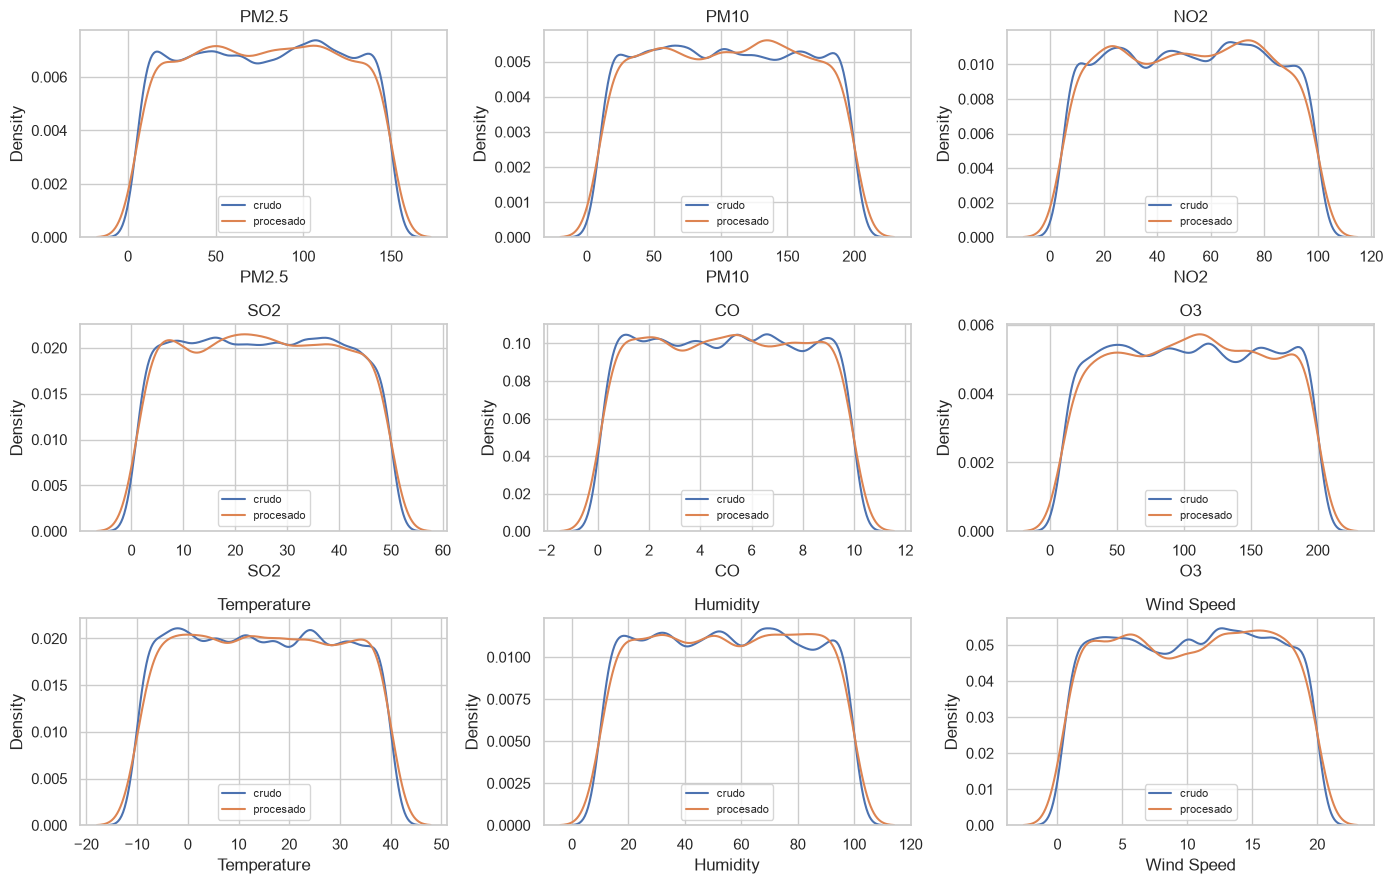

In [37]:
efecto = pd.DataFrame({
    "delta_media_%": ((df_procesado[NUM].mean() - df_raw[NUM].mean()) / df_raw[NUM].mean() * 100),
    "delta_std_%": ((df_procesado[NUM].std() - df_raw[NUM].std()) / df_raw[NUM].std() * 100),
    "KS_p": [stats.ks_2samp(df_raw[c].dropna(), df_procesado[c]).pvalue for c in NUM],
}).round(3)
efecto["misma_distribucion"] = efecto["KS_p"] > 0.05
display(efecto)

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, c in zip(axes.ravel(), NUM):
    sns.kdeplot(df_raw[c].dropna(), label="crudo", ax=ax)
    sns.kdeplot(df_procesado[c], label="procesado", ax=ax)
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## ¿Introdujo el pipeline correlaciones que no existían?

La interpolación por ciudad es el paso con más riesgo de inventar estructura, porque rellena
con valores vecinos. Se compara la matriz de Spearman antes y después.

Máximo cambio absoluto en una correlación: 0.0283


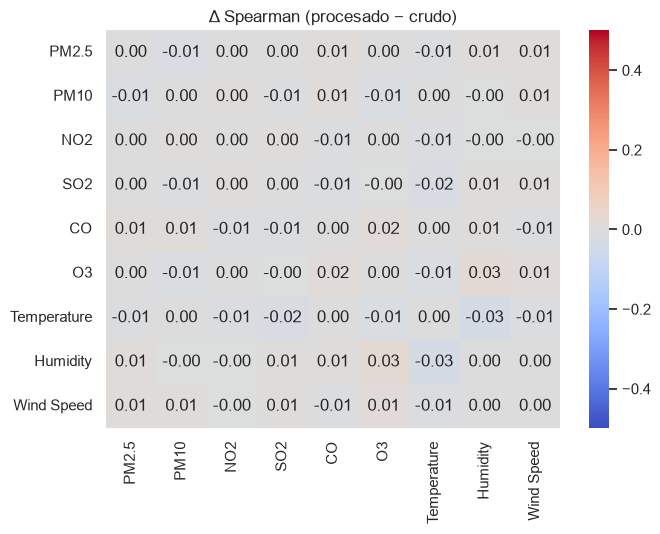

In [38]:
dif_corr = df_procesado[NUM].corr("spearman") - df_raw[NUM].corr("spearman")
print(f"Máximo cambio absoluto en una correlación: {dif_corr.abs().values.max():.4f}")

plt.figure(figsize=(7, 5.5))
sns.heatmap(dif_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-.5, vmax=.5)
plt.title("Δ Spearman (procesado − crudo)"); plt.tight_layout(); plt.show()

## Scorecard de integridad y exportación del dataset procesado

In [39]:
scorecard = pd.DataFrame([
    ("Filas", len(df_raw), len(df_procesado)),
    ("Columnas", df_raw.shape[1], df_procesado.shape[1]),
    ("Celdas nulas", int(df_raw.isna().sum().sum()), int(df_procesado.isna().sum().sum())),
    ("Duplicados exactos", int(df_raw.duplicated().sum()), int(df_procesado.duplicated().sum())),
    ("Ciudades distintas", df_raw["City"].nunique(), df_procesado["City"].nunique()),
    ("Fechas válidas (con el %d/%m/%Y original)",
     int(pd.to_datetime(df_raw["Date"], format="%d/%m/%Y", errors="coerce").notna().sum()),
     int(df_procesado["Date"].notna().sum())),
    ("Memoria (MB)", round(df_raw.memory_usage(deep=True).sum() / 1e6, 2),
     round(df_procesado.memory_usage(deep=True).sum() / 1e6, 2)),
], columns=["indicador", "antes", "después"]).set_index("indicador")
display(scorecard)

Path("data/processed").mkdir(parents=True, exist_ok=True)
SALIDA = "data/processed/air_quality_procesado.csv"
df_procesado.to_csv(SALIDA, index=False)
print(f"Exportado: {SALIDA} → {len(df_procesado):,} filas x {df_procesado.shape[1]} columnas")

,antes,después
indicador,,
Filas,30450.00,5075.00
Columnas,12.00,21.00
Celdas nulas,9277.00,0.00
Duplicados exactos,10495.00,0.00
Ciudades distintas,120.00,20.00
Fechas válidas (con el %d/%m/%Y original),13167.00,5075.00
Memoria (MB),7.35,1.48


Exportado: data/processed/air_quality_procesado.csv → 5,075 filas x 21 columnas


## Diccionario de datos y bitácora completa

In [40]:
DESCRIPCIONES = {
    "ratio_pm": "PM2.5 / PM10 (fracción fina)",
    "ratio_pm_imposible": "Marca ratio > 1, físicamente imposible",
    "n_excedencias_oms": "Guías OMS superadas en la fila (0-3)",
    "pm25_vs_ciudad": "PM2.5 menos la mediana de su ciudad",
    "pm25_movil_7d": "Media móvil de PM2.5 en ventana de 7 días",
    "pm25_delta": "Cambio de PM2.5 respecto al registro anterior de la ciudad",
    "trimestre_met": "Trimestre meteorológico (DEF/MAM/JJA/SON)",
    "mes_sin": "Codificación cíclica del mes (seno)",
    "mes_cos": "Codificación cíclica del mes (coseno)",
    "dia_sem_sin": "Codificación cíclica del día de semana (seno)",
    "dia_sem_cos": "Codificación cíclica del día de semana (coseno)",
    "mes": "Mes extraído de Date", "dia_semana": "Día de la semana (0=lunes)",
    "fin_semana": "Sábado o domingo", "viento_cat": "Cuartil de Wind Speed",
    "viento_ord": "viento_cat como entero ordenado (0-3)",
}
diccionario = pd.DataFrame({
    "tipo": df_procesado.dtypes.astype(str),
    "origen": ["original" if c in df_raw.columns else "derivada" for c in df_procesado.columns],
    "descripcion": [DESCRIPCIONES.get(c, "Columna original del dataset")
                    for c in df_procesado.columns],
})
display(diccionario)
display(pd.DataFrame(decisiones))

,tipo,origen,descripcion
City,object,original,Columna original del dataset
Country,object,original,Columna original del dataset
Date,datetime64[ns],original,Columna original del dataset
PM2.5,float64,original,Columna original del dataset
PM10,float64,original,Columna original del dataset
NO2,float64,original,Columna original del dataset
SO2,float64,original,Columna original del dataset
CO,float64,original,Columna original del dataset
O3,float64,original,Columna original del dataset
Temperature,float64,original,Columna original del dataset


,fase,columna,accion,justificacion
0,I-claves,City,Normalizar texto,120 variantes por mayúsculas/espacios → 20 reales
1,I-claves,Country,Normalizar texto,19 variantes por mayúsculas/espacios → 19 reales
2,I-claves,Date,Parsear con formato %m/%d/%Y,0 fechas inválidas (con %d/%m/%Y serían 17283)
3,III-duplicados,todas,Eliminar 13897 filas,Registros idénticos en todas las columnas
4,III-duplicados,City+Country+Date,Eliminar 11478 filas,Misma clave de negocio: se conserva el registr...
5,III-nulos,PM2.5,interpolacion (32 valores),0.6% de nulos en serie diaria por ciudad
6,III-nulos,PM10,interpolacion (24 valores),0.5% de nulos en serie diaria por ciudad
7,III-nulos,NO2,interpolacion (21 valores),0.4% de nulos en serie diaria por ciudad
8,III-nulos,SO2,interpolacion (29 valores),0.6% de nulos en serie diaria por ciudad
9,III-nulos,CO,interpolacion (25 valores),0.5% de nulos en serie diaria por ciudad
